# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Imports
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create connection to database
conn = sqlite3.connect('data.sqlite')

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [2]:
# California customers with a high credit limit (> 25,000), highest first
df_ca_high_credit = pd.read_sql("""
    SELECT customerNumber,
           customerName,
           contactFirstName,
           contactLastName,
           phone,
           city,
           state,
           CAST(creditLimit AS REAL) AS creditLimit
    FROM customers
    WHERE state = 'CA'
      AND CAST(creditLimit AS REAL) > 25000
    ORDER BY creditLimit DESC
""", conn)
df_ca_high_credit

,customerNumber,customerName,contactFirstName,contactLastName,phone,city,state,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,4155551450,San Rafael,CA,210500.0
1,239,Collectable Mini Designs Co.,Valarie,Thompson,7605558146,San Diego,CA,105000.0
2,321,Corporate Gift Ideas Co.,Julie,Brown,6505551386,San Francisco,CA,105000.0
3,205,Toys4GrownUps.com,Julie,Young,6265557265,Pasadena,CA,90700.0
4,161,Technics Stores Inc.,Juri,Hashimoto,6505556809,Burlingame,CA,84600.0
5,450,The Sharp Gifts Warehouse,Sue,Frick,4085553659,San Jose,CA,77600.0
6,129,Mini Wheels Co.,Julie,Murphy,6505555787,San Francisco,CA,64600.0
7,487,Signal Collectibles Ltd.,Sue,Taylor,4155554312,Brisbane,CA,60300.0
8,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,2155554369,Los Angeles,CA,57700.0
9,475,West Coast Collectables Co.,Steve,Thompson,3105553722,Burbank,CA,55400.0


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [3]:
# Non-US customers whose name contains "Collect" (Collectables, Collectibles, Collectors, Collections)
df_intl_collect = pd.read_sql("""
    SELECT customerNumber,
           customerName,
           contactFirstName,
           contactLastName,
           city,
           country
    FROM customers
    WHERE country != 'USA'
      AND customerName LIKE '%Collect%'
    ORDER BY country, customerName
""", conn)
df_intl_collect

,customerNumber,customerName,contactFirstName,contactLastName,city,country
0,471,"Australian Collectables, Ltd",Sean,Clenahan,Glen Waverly,Australia
1,114,"Australian Collectors, Co.",Peter,Ferguson,Melbourne,Australia
2,382,Salzburg Collectables,Georg,Pipps,Salzburg,Austria
3,260,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,Tsawassen,Canada
4,227,Heintze Collectables,Palle,Ibsen,Århus,Denmark
5,353,Reims Collectables,Paul,Henriot,Reims,France
6,415,"Bavarian Collectables Imports, Co.",Michael,Donnermeyer,Munich,Germany
7,409,Stuttgart Collectable Exchange,Rita,Müller,Stuttgart,Germany
8,211,"King Kong Collectables, Co.",Mike,Gao,Central Hong Kong,Hong Kong
9,189,"Clover Collections, Co.",Dean,Cassidy,Dublin,Ireland


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

**Answer:** The WHERE clause acts as a two-part checklist, and a customer is included only if it passes both checks:

1. **`country != 'USA'`** keeps every customer whose country is anything other than the United States, which removes all domestic accounts. I confirmed beforehand that US customers are always recorded exactly as `'USA'`, so no US customer can slip through under a different spelling.
2. **`customerName LIKE '%Collect%'`** searches inside each company name for the letters "Collect" anywhere in the name. The `%` signs mean "any text before or after," so it matches *Collectables*, *Collectibles*, *Collectors*, and *Collections*, and the match ignores capitalization.

The two checks are joined with **`AND`**, so a customer must be international **and** have "Collect" in its name. This returned 15 international partners. US companies with "Collect" in their name (for example, *Cambridge Collectables Co.*) were correctly excluded, as were international customers without "Collect" in their name.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [4]:
# Average credit limit per US state, with customer counts for context
df_state_credit = pd.read_sql("""
    SELECT state,
           COUNT(*) AS numCustomers,
           ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS avgCreditLimit
    FROM customers
    WHERE country = 'USA'
    GROUP BY state
    ORDER BY avgCreditLimit DESC
""", conn)
df_state_credit

,state,numCustomers,avgCreditLimit
0,NH,1,114200.00
1,NY,6,89966.67
2,PA,3,84766.67
3,CA,11,83854.55
4,NV,1,71800.00
5,MA,9,70755.56
6,CT,4,57350.00
7,NJ,1,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

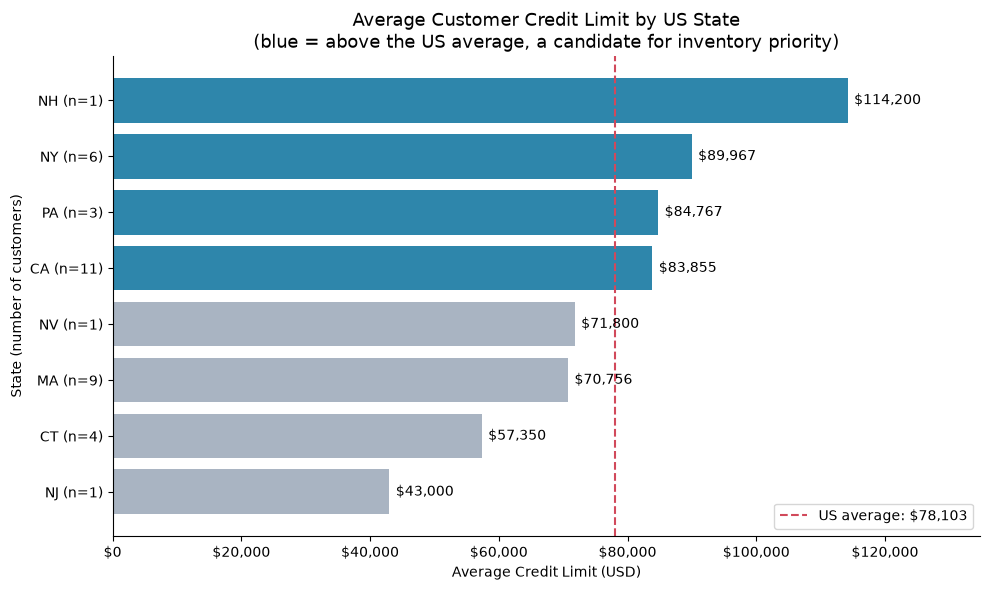

In [5]:
from matplotlib.ticker import FuncFormatter

# Sort ascending so the highest state appears at the top of a horizontal bar chart
plot_df = df_state_credit.sort_values('avgCreditLimit')
us_avg = pd.read_sql("""
    SELECT AVG(CAST(creditLimit AS REAL)) AS avg FROM customers WHERE country = 'USA'
""", conn)['avg'][0]

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2E86AB' if v >= us_avg else '#A9B4C2' for v in plot_df['avgCreditLimit']]
bars = ax.barh(plot_df['state'] + ' (n=' + plot_df['numCustomers'].astype(str) + ')',
               plot_df['avgCreditLimit'], color=colors)

# Value label on each bar
for bar, val in zip(bars, plot_df['avgCreditLimit']):
    ax.text(val + 1000, bar.get_y() + bar.get_height() / 2, f'${val:,.0f}', va='center', fontsize=10)

# Reference line for the overall US average
ax.axvline(us_avg, color='#D1495B', linestyle='--', linewidth=1.5, label=f'US average: ${us_avg:,.0f}')

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_title('Average Customer Credit Limit by US State\n(blue = above the US average, a candidate for inventory priority)', fontsize=13)
ax.set_xlabel('Average Credit Limit (USD)')
ax.set_ylabel('State (number of customers)')
ax.set_xlim(0, plot_df['avgCreditLimit'].max() * 1.18)
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [6]:
# Top 10 customers by total payment amount
df_top_customers = pd.read_sql("""
    SELECT c.customerNumber,
           c.customerName,
           COUNT(p.checkNumber) AS numPayments,
           ROUND(SUM(CAST(p.amount AS REAL)), 2) AS totalPayments
    FROM customers AS c
    JOIN payments AS p
        ON c.customerNumber = p.customerNumber
    GROUP BY c.customerNumber, c.customerName
    ORDER BY totalPayments DESC
    LIMIT 10
""", conn)
df_top_customers

,customerNumber,customerName,numPayments,totalPayments
0,141,Euro+ Shopping Channel,13,715738.98
1,124,Mini Gifts Distributors Ltd.,9,584188.24
2,114,"Australian Collectors, Co.",4,180585.07
3,151,Muscle Machine Inc,4,177913.95
4,148,"Dragon Souveniers, Ltd.",4,156251.03
5,323,"Down Under Souveniers, Inc",4,154622.08
6,187,"AV Stores, Co.",3,148410.09
7,276,"Anna's Decorations, Ltd",4,137034.22
8,321,Corporate Gift Ideas Co.,2,132340.78
9,146,"Saveley & Henriot, Co.",3,130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

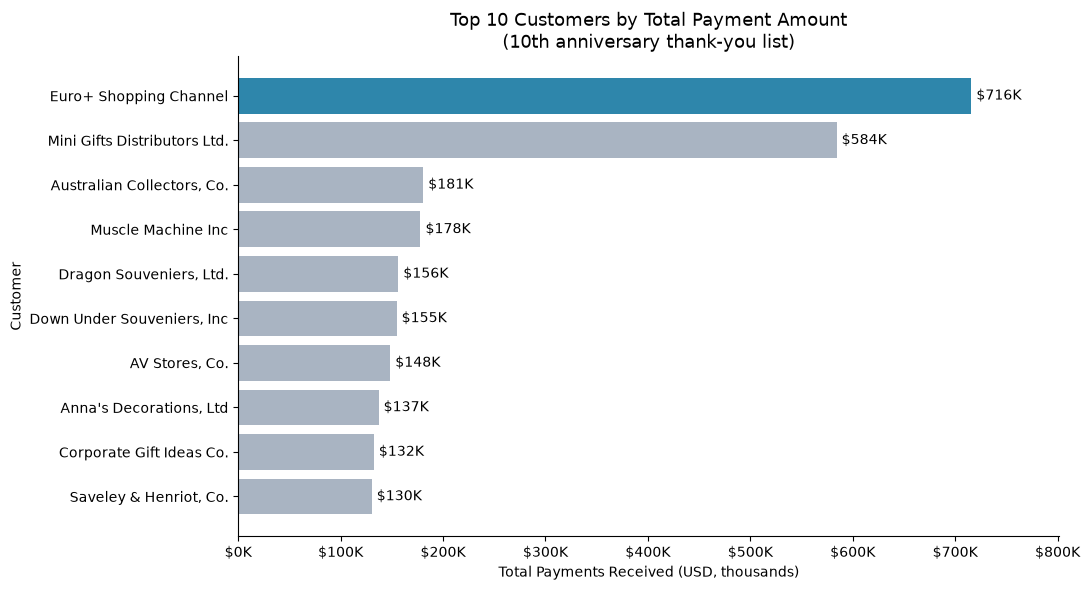

In [7]:
from matplotlib.ticker import FuncFormatter

plot_df = df_top_customers.sort_values('totalPayments')   # highest at the top

fig, ax = plt.subplots(figsize=(11, 6))
colors = ['#A9B4C2'] * (len(plot_df) - 1) + ['#2E86AB']   # highlight the #1 customer
bars = ax.barh(plot_df['customerName'], plot_df['totalPayments'], color=colors)

for bar, val in zip(bars, plot_df['totalPayments']):
    ax.text(val + 5000, bar.get_y() + bar.get_height() / 2, f'${val/1000:,.0f}K', va='center', fontsize=10)

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'${x/1000:,.0f}K'))
ax.set_title('Top 10 Customers by Total Payment Amount\n(10th anniversary thank-you list)', fontsize=13)
ax.set_xlabel('Total Payments Received (USD, thousands)')
ax.set_ylabel('Customer')
ax.set_xlim(0, plot_df['totalPayments'].max() * 1.12)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**Interpretation:** Two customers stand far above the rest: **Euro+ Shopping Channel ($716K over 13 payments)** and **Mini Gifts Distributors ($584K over 9 payments)**. Together they account for more than the next six customers combined, so they warrant the most personalized anniversary outreach. The remaining eight customers are closely grouped between $130K and $181K and can receive a consistent, still-personal thank-you.

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [8]:
# Products each customer has purchased in 10+ total units, sorted by total quantity (ascending)
df_customer_products = pd.read_sql("""
    SELECT c.customerNumber,
           c.customerName,
           p.productCode,
           p.productName,
           SUM(CAST(od.quantityOrdered AS INTEGER)) AS totalQuantity
    FROM customers AS c
    JOIN orders AS o
        ON c.customerNumber = o.customerNumber
    JOIN orderdetails AS od
        ON o.orderNumber = od.orderNumber
    JOIN products AS p
        ON od.productCode = p.productCode
    GROUP BY c.customerNumber, c.customerName, p.productCode, p.productName
    HAVING SUM(CAST(od.quantityOrdered AS INTEGER)) >= 10
    ORDER BY totalQuantity ASC
""", conn)

print("Rows:", len(df_customer_products))
print("Smallest total:", df_customer_products['totalQuantity'].min())
df_customer_products

Rows: 2531
Smallest total: 10


,customerNumber,customerName,productCode,productName,totalQuantity
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [9]:
# Per product line: number of distinct products and total quantity ordered
df_product_lines = pd.read_sql("""
    SELECT p.productLine,
           COUNT(DISTINCT p.productCode) AS numProducts,
           COALESCE(SUM(CAST(od.quantityOrdered AS INTEGER)), 0) AS totalQuantityOrdered
    FROM products AS p
    LEFT JOIN orderdetails AS od
        ON p.productCode = od.productCode
    GROUP BY p.productLine
    ORDER BY totalQuantityOrdered DESC
""", conn)
df_product_lines

,productLine,numProducts,totalQuantityOrdered
0,Classic Cars,38,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

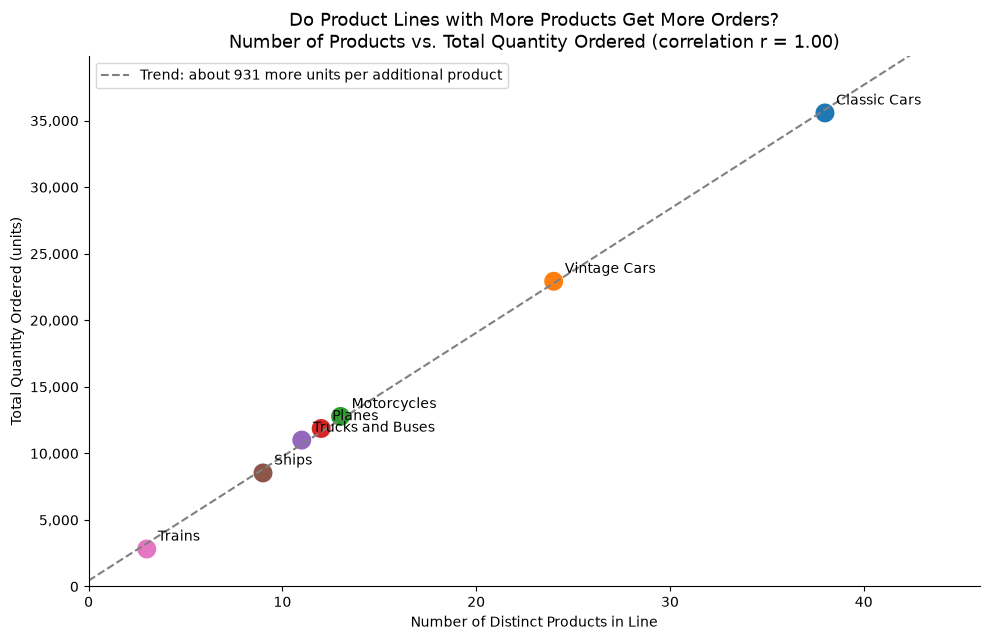

In [10]:
import numpy as np

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=df_product_lines, x='numProducts', y='totalQuantityOrdered',
                hue='productLine', s=220, palette='tab10', ax=ax, legend=False)

# Label each point with its product line
for _, row in df_product_lines.iterrows():
    ax.annotate(row['productLine'], (row['numProducts'], row['totalQuantityOrdered']),
                xytext=(8, 6), textcoords='offset points', fontsize=10)

# Linear trend line across the 7 product lines
slope, intercept = np.polyfit(df_product_lines['numProducts'], df_product_lines['totalQuantityOrdered'], 1)
x_vals = np.linspace(0, df_product_lines['numProducts'].max() + 5, 50)
ax.plot(x_vals, slope * x_vals + intercept, linestyle='--', color='grey',
        label=f'Trend: about {slope:,.0f} more units per additional product')

corr = df_product_lines['numProducts'].corr(df_product_lines['totalQuantityOrdered'])
ax.set_title(f'Do Product Lines with More Products Get More Orders?\n'
             f'Number of Products vs. Total Quantity Ordered (correlation r = {corr:.2f})', fontsize=13)
ax.set_xlabel('Number of Distinct Products in Line')
ax.set_ylabel('Total Quantity Ordered (units)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:,.0f}'))
ax.set_xlim(0, df_product_lines['numProducts'].max() + 8)
ax.set_ylim(0, df_product_lines['totalQuantityOrdered'].max() * 1.12)
ax.legend(loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

**Answer:** I chose a **scatter plot** because the question asks whether two numbers move together: the number of products in a line and the total quantity ordered. A scatter plot places each product line as one dot by both measures at once, so you can see the relationship directly. A bar chart could show only one measure at a time. I labeled each dot with its product line and added a dashed trend line so the pattern is easy to read.

**What it shows:** The dots fall almost perfectly on a straight line (correlation r = 1.00). Product lines with more products receive proportionally more orders: Classic Cars, with 38 products, leads with 35,582 units, and Trains, with only 3 products, has 2,818 units. However, every line sells roughly the **same amount per product (about 940–1,000 units each)**. So lines like Classic Cars are not more popular product for product; they simply offer more products.

**Business takeaway:** Adding well-chosen products to a line appears to grow its total demand, so **Trains (3 products)** and **Ships (9)** are candidates for expansion rather than phase-out, while Classic Cars and Vintage Cars justify the largest inventory allocations. This is based on only 7 product lines and shows a relationship, not proof of cause and effect, so new products should be piloted before large stock commitments.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [11]:
# Employees in offices with fewer than 5 employees, with job title, office, and supervisor
df_remote_offices = pd.read_sql("""
    SELECT e.employeeNumber,
           e.firstName,
           e.lastName,
           e.jobTitle,
           e.email,
           o.officeCode,
           o.city AS officeCity,
           o.country AS officeCountry,
           s.firstName || ' ' || s.lastName AS supervisorName,
           s.jobTitle AS supervisorTitle
    FROM employees AS e
    JOIN offices AS o
        ON e.officeCode = o.officeCode
    LEFT JOIN employees AS s
        ON e.reportsTo = s.employeeNumber
    WHERE e.officeCode IN (
        SELECT officeCode
        FROM employees
        GROUP BY officeCode
        HAVING COUNT(*) < 5
    )
    ORDER BY o.officeCode, e.lastName
""", conn)
df_remote_offices

,employeeNumber,firstName,lastName,jobTitle,email,officeCode,officeCity,officeCountry,supervisorName,supervisorTitle
0,1188,Julie,Firrelli,Sales Rep,jfirrelli@classicmodelcars.com,2,Boston,USA,Anthony Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,spatterson@classicmodelcars.com,2,Boston,USA,Anthony Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,ftseng@classicmodelcars.com,3,NYC,USA,Anthony Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,gvanauf@classicmodelcars.com,3,NYC,USA,Anthony Bow,Sales Manager (NA)
4,1625,Yoshimi,Kato,Sales Rep,ykato@classicmodelcars.com,5,Tokyo,Japan,Mami Nishi,Sales Rep
5,1621,Mami,Nishi,Sales Rep,mnishi@classicmodelcars.com,5,Tokyo,Japan,Mary Patterson,VP Sales
6,1611,Andy,Fixter,Sales Rep,afixter@classicmodelcars.com,6,Sydney,Australia,William Patterson,Sales Manager (APAC)
7,1619,Tom,King,Sales Rep,tking@classicmodelcars.com,6,Sydney,Australia,William Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,pmarsh@classicmodelcars.com,6,Sydney,Australia,William Patterson,Sales Manager (APAC)
9,1088,William,Patterson,Sales Manager (APAC),wpatterson@classicmodelcars.com,6,Sydney,Australia,Mary Patterson,VP Sales


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

**Answer:** I broke the request into two questions: *which offices are small?* and *who works in them?*

1. **Subquery (finds the offices):** `SELECT officeCode FROM employees GROUP BY officeCode HAVING COUNT(*) < 5` groups employees by office, counts each group, and keeps only offices with fewer than 5 people. It returns a list of office codes (2, 3, 5, 6, 7) and is calculated from the data at run time, so no codes are hard-coded. If staffing changes, the query automatically adjusts.
2. **Main query (returns the employees):** `WHERE e.officeCode IN (...)` keeps only employees whose office code appears in that list. The outer query then joins `offices` for each employee's location and **self-joins `employees`** (matching `reportsTo` to `employeeNumber`) to look up each supervisor's name and title. I used a `LEFT JOIN` for the supervisor so that an employee without a manager would still appear rather than being dropped.

The result is 12 employees in 5 offices. Most of them already report to a manager in a different office (for example, the Boston and NYC reps report to Anthony Bow in San Francisco), which suggests remote supervision already works and supports the move to remote work. One data-quality note: the source data spells Gerard Bondur's title as "Sale Manager (EMEA)", which would be standardized in cleaning.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [12]:
# Close the connection to data.sqlite (Part 2 opens its own connection, conn4)
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [13]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [14]:
# Part 2 - Initial Exploration: scope of the database
tables = ['movie_basics', 'movie_ratings', 'movie_akas', 'directors',
          'writers', 'principals', 'known_for', 'persons']
table_sizes = pd.DataFrame(
    [(t, pd.read_sql(f"SELECT COUNT(*) AS n FROM {t}", conn4)['n'][0]) for t in tables],
    columns=['table', 'rows'])
print(table_sizes.to_string(index=False))

# Year coverage and out-of-scope rows
year_scope = pd.read_sql("""
    SELECT MIN(start_year) AS minYear,
           MAX(start_year) AS maxYear,
           SUM(CASE WHEN start_year > 2019 THEN 1 ELSE 0 END) AS moviesAfter2019,
           COUNT(*) AS totalMovies
    FROM movie_basics
""", conn4)
year_scope

        table    rows
 movie_basics  146144
movie_ratings   73856
   movie_akas  331703
    directors  291174
      writers  255873
   principals 1028186
    known_for 1638260
      persons  606648


,minYear,maxYear,moviesAfter2019,totalMovies
0,2010,2115,1063,146144


In [15]:
# Null / coverage check for in-scope movies (start_year 2010-2019)
null_check = pd.read_sql("""
    SELECT COUNT(*) AS moviesInScope,
           SUM(CASE WHEN mb.runtime_minutes IS NULL THEN 1 ELSE 0 END) AS nullRuntime,
           SUM(CASE WHEN mb.genres IS NULL THEN 1 ELSE 0 END) AS nullGenres,
           SUM(CASE WHEN mr.movie_id IS NULL THEN 1 ELSE 0 END) AS noRating,
           SUM(CASE WHEN mb.runtime_minutes IS NOT NULL AND mb.genres IS NOT NULL
                     AND mr.movie_id IS NOT NULL THEN 1 ELSE 0 END) AS completeRows
    FROM movie_basics AS mb
    LEFT JOIN movie_ratings AS mr
        ON mb.movie_id = mr.movie_id
    WHERE mb.start_year <= 2019
""", conn4)
null_check

,moviesInScope,nullRuntime,nullGenres,noRating,completeRows
0,145081,30765,5359,71225,65720


In [16]:
# How genres are stored, and runtime extremes (possible outliers)
genre_sample = pd.read_sql("""
    SELECT genres, COUNT(*) AS n
    FROM movie_basics
    WHERE start_year <= 2019 AND genres IS NOT NULL
    GROUP BY genres
    ORDER BY n DESC
    LIMIT 8
""", conn4)
runtime_range = pd.read_sql("""
    SELECT MIN(runtime_minutes) AS minRuntime, MAX(runtime_minutes) AS maxRuntime,
           ROUND(AVG(runtime_minutes), 1) AS avgRuntime
    FROM movie_basics
    WHERE start_year <= 2019 AND runtime_minutes IS NOT NULL
""", conn4)
print(runtime_range.to_string(index=False), "\n")
genre_sample

 minRuntime  maxRuntime  avgRuntime
        1.0     51420.0        86.2 



,genres,n
0,Documentary,32106
1,Drama,21306
2,Comedy,9096
3,Horror,4309
4,"Comedy,Drama",3497
5,Thriller,2984
6,Action,2164
7,"Biography,Documentary",2115


In [17]:
# Genre-level reception: rated, in-scope movies with genres (nulls excluded, not filled)
rated = pd.read_sql("""
    SELECT mb.movie_id, mb.primary_title, mb.start_year, mb.genres,
           mr.averagerating, mr.numvotes
    FROM movie_basics AS mb
    JOIN movie_ratings AS mr
        ON mb.movie_id = mr.movie_id
    WHERE mb.start_year <= 2019
      AND mb.genres IS NOT NULL
""", conn4)

# Split "Comedy,Drama" into one row per genre (a movie counts toward each of its genres)
rated_genres = rated.assign(genre=rated['genres'].str.split(',')).explode('genre')

genre_stats = (rated_genres.groupby('genre')
               .agg(numMovies=('movie_id', 'count'),
                    avgRating=('averagerating', 'mean'),
                    medianVotes=('numvotes', 'median'),
                    totalVotes=('numvotes', 'sum'))
               .round(2)
               .sort_values('totalVotes', ascending=False))
print("Rated movies with genres:", len(rated))
genre_stats.head(12)

Rated movies with genres: 73052


,numMovies,avgRating,medianVotes,totalVotes
genre,,,,
Drama,30788,6.40,71.0,119567500
Action,6988,5.81,170.0,101161682
Adventure,3817,6.20,111.0,84232589
Comedy,17290,6.00,95.0,74305805
Thriller,8217,5.64,132.0,48155313
Sci-Fi,2206,5.49,126.5,42960289
Crime,4611,6.12,169.0,39631356
Romance,6589,6.15,116.0,26913873
Fantasy,2126,5.92,89.0,26335704


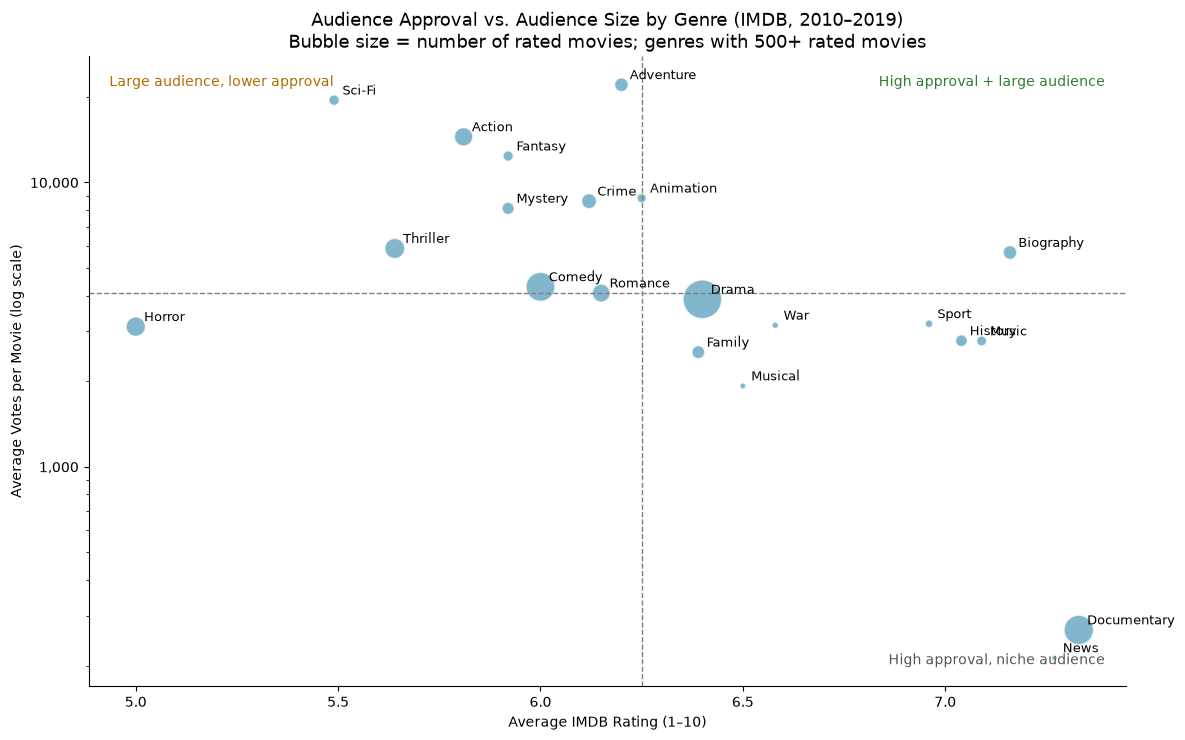

,numMovies,avgRating,avgVotesPerMovie
genre,,,
Adventure,3817,6.2,22067.7
Sci-Fi,2206,5.5,19474.3
Action,6988,5.8,14476.5
Fantasy,2126,5.9,12387.4
Animation,1743,6.2,8808.5
Crime,4611,6.1,8595.0
Mystery,3039,5.9,8113.6
Thriller,8217,5.6,5860.4
Biography,3809,7.2,5673.3


In [18]:
# Business question visual: approval (rating) vs. audience size (votes per movie) by genre
plot_df = genre_stats[genre_stats['numMovies'] >= 500].copy()
plot_df['avgVotesPerMovie'] = plot_df['totalVotes'] / plot_df['numMovies']

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.scatter(plot_df['avgRating'], plot_df['avgVotesPerMovie'],
           s=plot_df['numMovies'] / 40, alpha=0.6, color='#2E86AB', edgecolor='white')
for genre, row in plot_df.iterrows():
    ax.annotate(genre, (row['avgRating'], row['avgVotesPerMovie']),
                xytext=(6, 4), textcoords='offset points', fontsize=9)

# Median lines split the chart into four quadrants
x_med, y_med = plot_df['avgRating'].median(), plot_df['avgVotesPerMovie'].median()
ax.axvline(x_med, color='grey', linestyle='--', linewidth=1)
ax.axhline(y_med, color='grey', linestyle='--', linewidth=1)
ax.text(0.98, 0.97, 'High approval + large audience', transform=ax.transAxes, ha='right', va='top', color='#2E7D32', fontsize=10)
ax.text(0.02, 0.97, 'Large audience, lower approval', transform=ax.transAxes, ha='left', va='top', color='#B26A00', fontsize=10)
ax.text(0.98, 0.03, 'High approval, niche audience', transform=ax.transAxes, ha='right', va='bottom', color='#555555', fontsize=10)

ax.set_yscale('log')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:,.0f}'))
ax.set_title('Audience Approval vs. Audience Size by Genre (IMDB, 2010–2019)\n'
             'Bubble size = number of rated movies; genres with 500+ rated movies', fontsize=13)
ax.set_xlabel('Average IMDB Rating (1–10)')
ax.set_ylabel('Average Votes per Movie (log scale)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

plot_df.sort_values('avgVotesPerMovie', ascending=False)[['numMovies', 'avgRating', 'avgVotesPerMovie']].round(1)

In [19]:
# Data-quality evidence for the cleaning task list (in-scope movies only)
quality = pd.read_sql("""
    SELECT
        SUM(CASE WHEN runtime_minutes < 40 THEN 1 ELSE 0 END)  AS runtimeUnder40,
        SUM(CASE WHEN runtime_minutes > 300 THEN 1 ELSE 0 END) AS runtimeOver300,
        SUM(CASE WHEN genres LIKE '%,%' THEN 1 ELSE 0 END)     AS multiGenreRows,
        COUNT(*) - COUNT(DISTINCT primary_title || start_year) AS duplicateTitleYear
    FROM movie_basics
    WHERE start_year <= 2019
""", conn4)
low_votes = pd.read_sql("""
    SELECT SUM(CASE WHEN numvotes < 50 THEN 1 ELSE 0 END) AS ratedUnder50Votes,
           COUNT(*) AS ratedMovies
    FROM movie_ratings
""", conn4)
print(quality.to_string(index=False), "\n")
print(low_votes.to_string(index=False))

 runtimeUnder40  runtimeOver300  multiGenreRows  duplicateTitleYear
           5209             123           59022                2057 

 ratedUnder50Votes  ratedMovies
             37032        73856


## Initial Exploration Findings

- **Scope:** `movie_basics` holds 146,144 movies. 1,063 have a `start_year` after 2019 (some as late as 2115) and were excluded, leaving **145,081 in-scope movies (2010–2019)**.
- **Completeness:** only **65,720 movies (45%)** have runtime, genres, and a rating all present. About **49% of in-scope movies have no rating** and **21% have no runtime**. Nulls were excluded, not filled.
- **Genre volume vs. audience:** Documentary and Drama dominate by count, but Documentary averages only **267 votes per movie**, while Adventure (22,068), Sci-Fi (19,474), and Action (14,477) attract far larger audiences.
- **Approval vs. audience trade-off:** factual genres rate highest (Documentary 7.3, News 7.3, Biography 7.2) but draw small audiences; blockbuster genres draw the largest audiences but rate lower (Sci-Fi 5.5, Action 5.8). Horror has the lowest average rating (5.0).
- **Biography is the standout:** it is the only genre clearly above the median for both rating and votes per movie. However, its median is only 40 votes, so a few hit biopics drive its average.
- **Engagement is skewed:** half of all rated movies (37,032 of 73,856) have fewer than 50 votes, so averages are pulled up by a small number of popular titles.

## Business Question

**Which movie genres combine strong audience approval with a large audience, and how should a studio balance high-engagement genres (Adventure, Action, Sci-Fi) against high-rated but niche genres (Biography, Documentary) when choosing what to produce?**

**Why it matters:** the visual shows a clear trade-off. Genres that draw the largest audiences rate below average, while the best-rated genres reach small audiences. **Biography** is the only genre clearly in the high-approval, large-audience quadrant, and **Adventure** and **Animation** sit on its edge. A deeper analysis would test whether combining genres (for example, *Biography + Drama* or *Adventure + Animation*) captures both strengths, and would add runtime and director track record to the comparison.

## Potential Data Cleaning Tasks

1. **Remove out-of-scope years:** 1,063 movies have `start_year` > 2019 (up to 2115).
2. **Null handling:** 71,225 in-scope movies lack a rating, 30,765 lack a runtime, and 5,359 lack genres. Exclude them per analysis (do not impute) and report the reduced sample size (65,720 complete rows).
3. **Normalize genres:** 59,022 movies store several genres in one comma-separated string (`"Comedy,Drama"`). Split them into a separate movie–genre table so each genre can be counted and joined cleanly.
4. **Runtime outliers:** runtimes range from 1 to 51,420 minutes. 5,209 are under 40 minutes (likely shorts) and 123 are over 300 minutes (likely errors or series). Set valid bounds or flag them.
5. **Low-vote ratings:** 37,032 of 73,856 rated movies have fewer than 50 votes. Set a minimum vote threshold so averages aren't distorted by a handful of reviewers.
6. **Possible duplicates:** 2,057 movies share a title and year with another entry. Verify by `movie_id` and director whether they are true duplicates or different films with the same name.
7. **Standardize text fields:** trim whitespace and standardize capitalization in titles and genre names before grouping or joining.

In [20]:
# Close the IMDB database connection
conn4.close()